# Adult Income Prediction

## Task 1: Dataset Selection and Problem Statement
This project uses supervised binary classification to predict whether a person's annual income exceeds $50,000. The target is income, where 0 means at or below $50,000 and 1 means above $50,000.

- **Dataset:** Adult (Census Income)
- **Source:** https://archive.ics.uci.edu/dataset/2/adult
- **Citation:** Becker, B., & Kohavi, R. (1996). Adult [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5XW20

The combined CSV contains all 48,842 rows from adult.data and adult.test, with the original data values retained before cleaning. Place adult.csv beside the notebook to rerun it.

## Task 2: Load and Inspect the Data

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay,
    accuracy_score, confusion_matrix, f1_score, precision_score,
    recall_score, roc_auc_score,
)
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Read the combined CSV from the notebook directory.
df = pd.read_csv("adult.csv")

print(f"Rows: {len(df):,} | Columns: {df.shape[1]}")
display(df.head())
# Check inferred types and non-null counts before cleaning.
df.info()
display(df.dtypes.rename("Data type").to_frame())

Rows: 48,842 | Columns: 15


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


<class 'pandas.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             48842 non-null  int64
 1   workclass       48842 non-null  str  
 2   fnlwgt          48842 non-null  int64
 3   education       48842 non-null  str  
 4   education_num   48842 non-null  int64
 5   marital_status  48842 non-null  str  
 6   occupation      48842 non-null  str  
 7   relationship    48842 non-null  str  
 8   race            48842 non-null  str  
 9   sex             48842 non-null  str  
 10  capital_gain    48842 non-null  int64
 11  capital_loss    48842 non-null  int64
 12  hours_per_week  48842 non-null  int64
 13  native_country  48842 non-null  str  
 14  income          48842 non-null  str  
dtypes: int64(6), str(9)
memory usage: 5.6 MB


,Data type
age,int64
workclass,str
fnlwgt,int64
education,str
education_num,int64
marital_status,str
occupation,str
relationship,str
race,str
sex,str


### Data Quality Issues

In [2]:
text_columns = df.select_dtypes(include=["object", "string"]).columns
# Trim whitespace before counting the literal missing-value marker.
placeholder_counts = df[text_columns].apply(lambda column: column.str.strip().eq("?").sum())
display(placeholder_counts[placeholder_counts.gt(0)].rename("Question mark count").to_frame())
display(df["income"].value_counts(dropna=False).rename("Raw label count").to_frame())
print(f"Existing null cells: {df.isna().sum().sum():,}")
print(f"Raw exact duplicate rows: {df.duplicated().sum():,}")

,Question mark count
workclass,2799
occupation,2809
native_country,857


,Raw label count
income,
<=50K,24720
<=50K.,12435
>50K,7841
>50K.,3846


Existing null cells: 0
Raw exact duplicate rows: 29


Question marks mark missing values in workclass (5.7%), occupation (5.8%), and native_country (1.8%). The original test-file income labels end in a period. The combined data contain 29 raw exact duplicates, and the target is roughly 76% at or below $50K and 24% above $50K.

## Task 3: Data Preparation and Preprocessing

In [3]:
clean = df.copy()
# Remove surrounding whitespace so equivalent categories match.
for column in text_columns:
    clean[column] = clean[column].str.strip()
# Convert the placeholder to a missing value the imputer can handle.
clean = clean.replace("?", float("nan"))
# Strip the trailing period used on labels in adult.test.
target = clean["income"].str.rstrip(".").map({"<=50K": 0, ">50K": 1})
if target.isna().any():
    raise ValueError("Missing or unexpected income labels after normalization.")
clean["income"] = target.astype(int)
# Recount duplicates after label normalization so identical records stay out of separate splits.
duplicates_removed = int(clean.duplicated().sum())
clean = clean.drop_duplicates().reset_index(drop=True)
print(f"Duplicate rows removed after normalization: {duplicates_removed:,}")
display(clean["income"].value_counts().rename("Clean label count").to_frame())

Duplicate rows removed after normalization: 52


,Clean label count
income,
0,37109
1,11681


Removing the period exposes 23 additional duplicate rows across the original UCI splits, bringing the total removed to 52. The pipeline uses Unknown for missing categories because missingness may carry information and a most-frequent fill would hide it. Numeric scaling keeps units from driving the effect of regularization in logistic regression. Fitting the transformers inside the pipeline keeps held-out data out of preprocessing, including within each cross-validation fold.

### Train/Test Split

Use a reproducible 80/20 random split of the combined file. Stratification preserves the approximate proportion of each income class. The test rows are held out from model fitting.

In [4]:
# Keep demographic fields for subgroup evaluation.
audit_columns = ["sex", "race"]
# Remove the target, sampling weight, and education label already represented by education_num.
drop_columns = ["income", "fnlwgt", "education", *audit_columns]
X = clean.drop(columns=drop_columns)
y = clean["income"]
# Preserve the target proportions in both sets.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)
display(pd.DataFrame({
    "Rows": [len(y_train), len(y_test)],
    "Above $50K share": [y_train.mean(), y_test.mean()],
}, index=["Train", "Test"]).round(4))

,Rows,Above $50K share
Train,39032,0.2394
Test,9758,0.2394


Stratification preserves the approximate 76/24 class ratio in both sets. I drop fnlwgt because it is a Census sampling weight and drop education because education_num already encodes the same information. I keep sex and race only for the audit so the model does not use them directly. Other features can still act as proxies.

## Task 4: Select and Train a Machine Learning Model

Compare logistic regression with a majority-class baseline. One-hot encoding represents nominal categories without imposing an ordering. Scaling places numeric features on comparable scales for regularized logistic regression.

In [5]:
# Choose transformations by feature type using the training columns.
numeric_columns = X_train.select_dtypes(include="number").columns
categorical_columns = X_train.columns.difference(numeric_columns)
# Bundle preprocessing so each training fold fits its own transformers.
preprocessor = ColumnTransformer([
    ("numeric", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ]), numeric_columns),
    ("categorical", Pipeline([
        # Keep missingness visible as a separate category.
        ("impute", SimpleImputer(strategy="constant", fill_value="Unknown")),
        # Allow categories that appear only in validation or test rows.
        ("encode", OneHotEncoder(handle_unknown="ignore")),
    ]), categorical_columns),
])
models = {
    "Majority baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": Pipeline([
        ("preprocess", preprocessor),
        ("classifier", LogisticRegression(max_iter=2000)),
    ]),
}
# Fit both models on the same training rows for comparison.
for model in models.values():
    model.fit(X_train, y_train)
# Estimate F1 across five training folds before evaluating on the held-out test set.
cv_f1 = cross_val_score(models["Logistic regression"], X_train, y_train, cv=5, scoring="f1")
print(f"Training-set cross-validation F1 by fold: {cv_f1.round(3)}")
print(f"Mean F1 ± standard deviation: {cv_f1.mean():.3f} ± {cv_f1.std():.3f}")

Training-set cross-validation F1 by fold: [0.655 0.658 0.64  0.646 0.672]
Mean F1 ± standard deviation: 0.654 ± 0.011


Logistic regression is an interpretable baseline whose model is linear in the log-odds. Five-fold cross-validation on the training set shows how much F1 varies across folds. The final evaluation uses the held-out test set.

## Task 5: Evaluate Model Performance

Use >50K as the positive class and classify a row as positive when its predicted probability exceeds 0.50. Precision measures how often positive predictions are correct. Recall measures how many actual positive cases the model finds. ROC-AUC evaluates ranking across thresholds. The precision–recall curve shows the trade-off for the smaller income class.

,Accuracy,Precision,Recall,F1,ROC-AUC
Majority baseline,0.761,0.000,0.000,0.000,0.500
Logistic regression,0.855,0.737,0.615,0.671,0.909


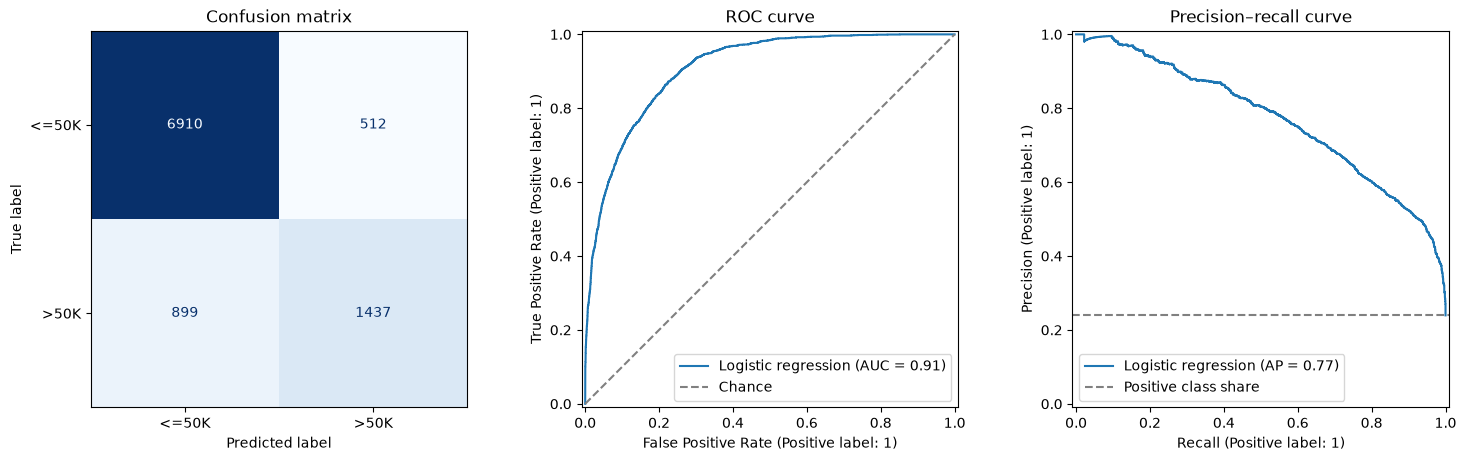

False positives: 512 | False negatives: 899


In [6]:
# Apply the same decision threshold across models and demographic groups.
threshold = 0.50
model_name = "Logistic regression"
predictions, probabilities, scores = {}, {}, {}
for name, model in models.items():
    # Use positive-class probabilities for ROC-AUC and threshold them for classification metrics.
    probability = model.predict_proba(X_test)[:, 1]
    prediction = (probability > threshold).astype(int)
    probabilities[name] = probability
    predictions[name] = prediction
    scores[name] = {
        "Accuracy": accuracy_score(y_test, prediction),
        "Precision": precision_score(y_test, prediction, zero_division=0),
        "Recall": recall_score(y_test, prediction),
        "F1": f1_score(y_test, prediction, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probability),
    }
display(pd.DataFrame(scores).T.round(3))

# Plot error counts and show performance across thresholds.
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), layout="constrained")
ConfusionMatrixDisplay.from_predictions(
    y_test, predictions[model_name], display_labels=["<=50K", ">50K"],
    colorbar=False, cmap="Blues", ax=axes[0],
)
RocCurveDisplay.from_predictions(y_test, probabilities[model_name], ax=axes[1], name=model_name)
axes[1].plot([0, 1], [0, 1], "--", color="gray", label="Chance")
axes[1].legend(loc="lower right")
PrecisionRecallDisplay.from_predictions(
    y_test, probabilities[model_name], ax=axes[2], name=model_name
)
axes[2].axhline(y_test.mean(), linestyle="--", color="gray", label="Positive class share")
axes[2].legend(loc="lower left")
for ax, title in zip(axes, ["Confusion matrix", "ROC curve", "Precision–recall curve"]):
    ax.set_title(title)
plt.show()
tn, fp, fn, tp = confusion_matrix(y_test, predictions[model_name], labels=[0, 1]).ravel()
print(f"False positives: {fp:,} | False negatives: {fn:,}")

### Fairness and Bias Check

Compare results by the recorded sex and race categories separately using the same test predictions and threshold. True positive rate (TPR) measures the share of actual >$50K cases correctly identified. False positive rate (FPR) measures the share of actual <=$50K cases predicted above $50K. Compare group sizes and denominators before interpreting gaps. Rates with a zero denominator are undefined.

In [7]:
# Align demographic fields to the held-out rows using their original indices.
audit = clean.loc[X_test.index, audit_columns].copy()
audit["actual"] = y_test
audit["predicted"] = predictions[model_name]
subgroup_results = {}
for attribute in audit_columns:
    rows = []
    for group, records in audit.groupby(attribute, dropna=False):
        actual = records["actual"].eq(1)
        predicted = records["predicted"].eq(1)
        positives = int(actual.sum())
        negatives = len(records) - positives
        # Leave TPR or FPR undefined when its denominator is zero.
        rows.append({
            "Group": group, "Rows": len(records),
            "Actual positives": positives, "Actual negatives": negatives,
            "Actual positive rate": actual.mean(),
            "Predicted positive rate": predicted.mean(),
            "TPR": (actual & predicted).sum() / positives if positives else float("nan"),
            "FPR": (~actual & predicted).sum() / negatives if negatives else float("nan"),
        })
    result = pd.DataFrame(rows).set_index("Group")
    subgroup_results[attribute] = result
    print(f"Results by {attribute}")
    display(result.round(3))
    # Limit reported gaps to groups with enough actual positives and negatives.
    eligible = result[(result["Actual positives"] >= 30) & (result["Actual negatives"] >= 30)]
    for metric in ["Predicted positive rate", "TPR", "FPR"]:
        rates = eligible[metric].dropna()
        if len(rates) >= 2:
            print(f"{metric} gap: {(rates.max() - rates.min()) * 100:.1f} percentage points "
                  f"({rates.idxmax()} vs. {rates.idxmin()})")

Results by sex


,Rows,Actual positives,Actual negatives,Actual positive rate,Predicted positive rate,TPR,FPR
Group,,,,,,,
Female,3326,383,2943,0.115,0.073,0.496,0.018
Male,6432,1953,4479,0.304,0.265,0.639,0.103


Predicted positive rate gap: 19.3 percentage points (Male vs. Female)
TPR gap: 14.2 percentage points (Male vs. Female)
FPR gap: 8.5 percentage points (Male vs. Female)
Results by race


,Rows,Actual positives,Actual negatives,Actual positive rate,Predicted positive rate,TPR,FPR
Group,,,,,,,
Amer-Indian-Eskimo,94,13,81,0.138,0.117,0.615,0.037
Asian-Pac-Islander,311,71,240,0.228,0.228,0.634,0.108
Black,916,113,803,0.123,0.083,0.478,0.027
Other,84,10,74,0.119,0.083,0.400,0.041
White,8353,2129,6224,0.255,0.214,0.623,0.074


Predicted positive rate gap: 14.5 percentage points (Asian-Pac-Islander vs. Black)
TPR gap: 15.6 percentage points (Asian-Pac-Islander vs. Black)
FPR gap: 8.1 percentage points (Asian-Pac-Islander vs. Black)


Gap calculations require at least 30 actual positives and 30 actual negatives per group. All groups remain visible in the audit table. Among eligible race groups, the TPR gap was 15.6 percentage points. The Other category had 10 actual positives, so one case would move its TPR by 10.0 percentage points.

## Task 6: Notebook Summary

I trained a supervised binary classifier to predict whether annual income exceeded $50,000. I standardized the labels, handled missing values, removed 52 duplicates, and used a stratified 80/20 split. On the held-out test set, logistic regression achieved 0.855 accuracy, 0.671 F1, and 0.909 ROC-AUC, while the majority-class baseline had zero recall. The model produced 899 false negatives and 512 false positives. The true positive rate was 0.496 for women and 0.639 for men, a 14.2-percentage-point gap, and small subgroup counts limited interpretation of the race comparison.